## 회고 및 비교분석

회고:
- 스크롤이 길어질 수록 모델 성능을 비교하기가 번~거롭다! 이건 뭔가 side by side로 놓고 비교해볼 수 있는 툴 개발이 필요해보인다.
    - 이미 있는데 내가 모르는 거겠지.. 이렇게 쓰면 퍼실님이 알려주시겠지..
- 원인 모를 많은 메모리관련 오류들이 단순히 끄고 다시 켜는 것으로 해결이 되는 상황들을 몇번 경험했다. 
- 유의미한 분석을 할 만큼 에포크를 많이 돌려보지 못했다.
- 주로 디버깅을 하는 데 시간을 소요함
    - 텐서플로우의 혼합정밀도 사용 시 옵티마이저가 이미 LossScaleOptimizer로 래핑되어서 발생하는 문제 
    - dice_loss() 함수 내 변수가 리스트로 인식되어 호출이 안되는 문제
    - 모델을 바꾸고 난 뒤에 체크포인트 저장이 안되는 문제

### 모델 1: 인코더-디코더

mean_iou: 0.4002039118443837
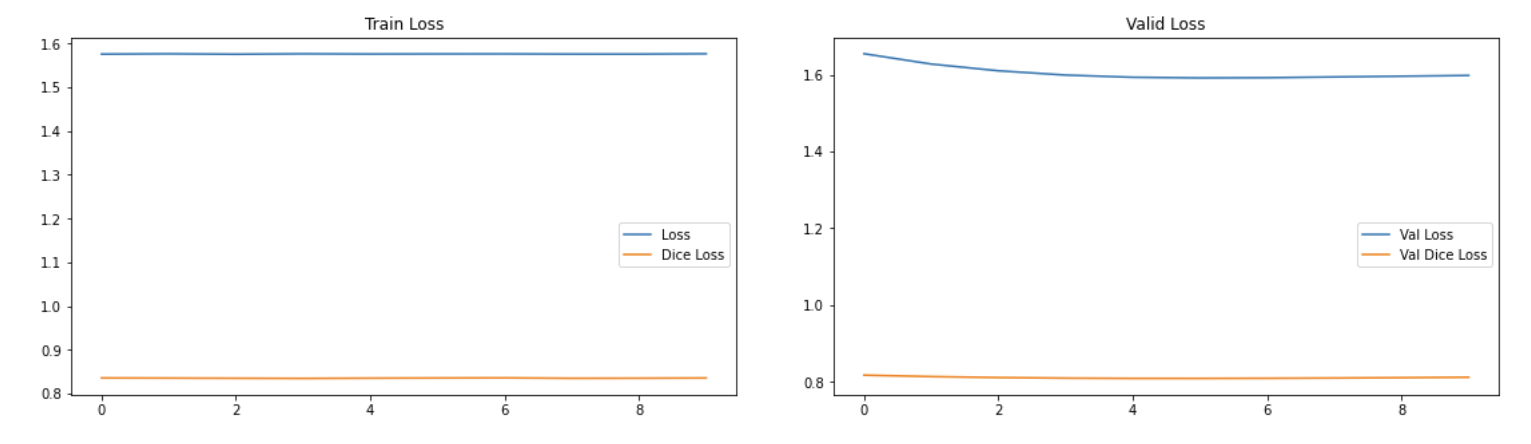
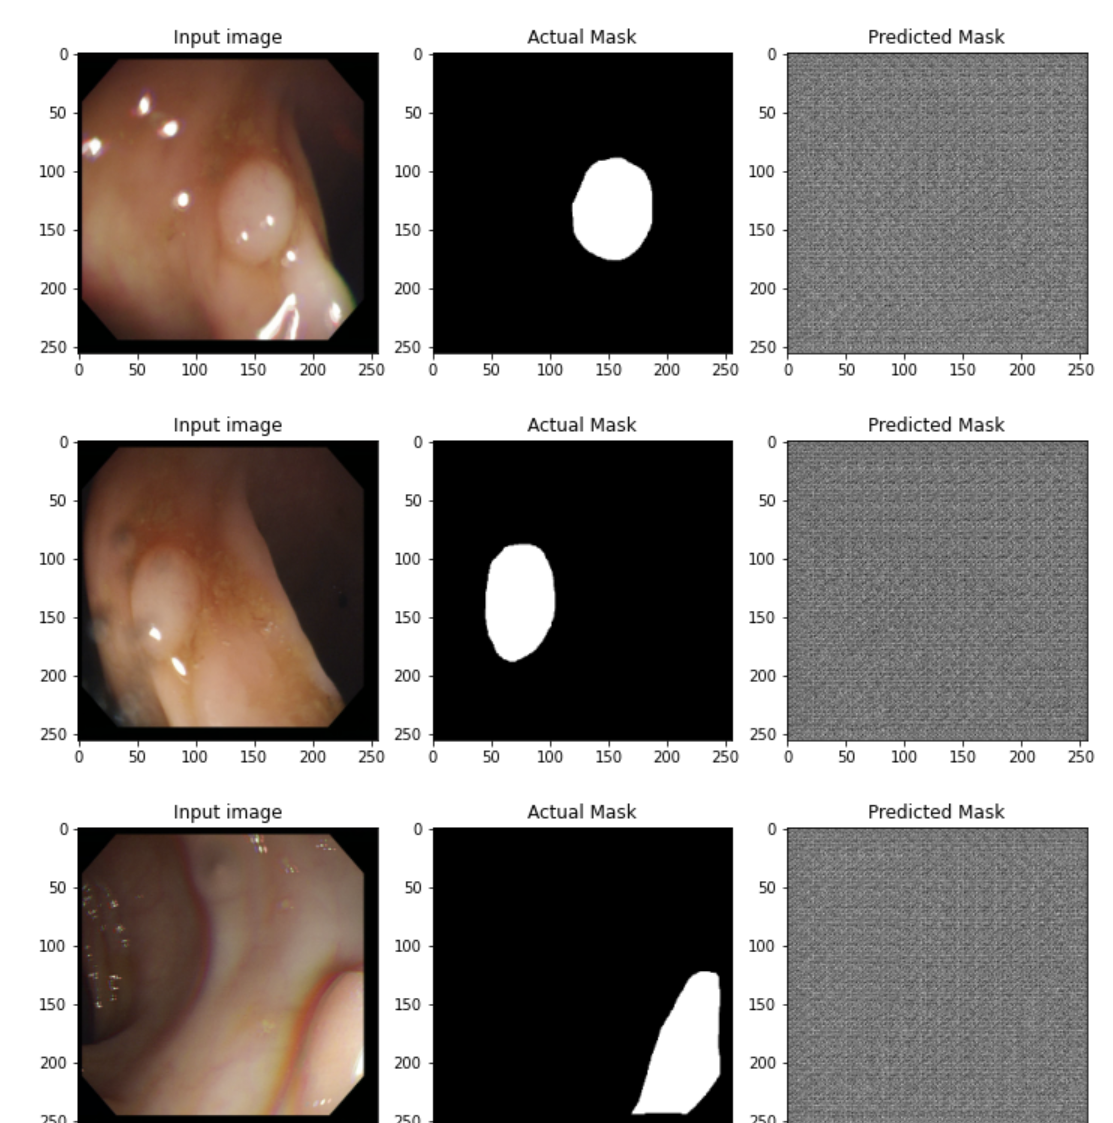

### 모델 2: U-Net

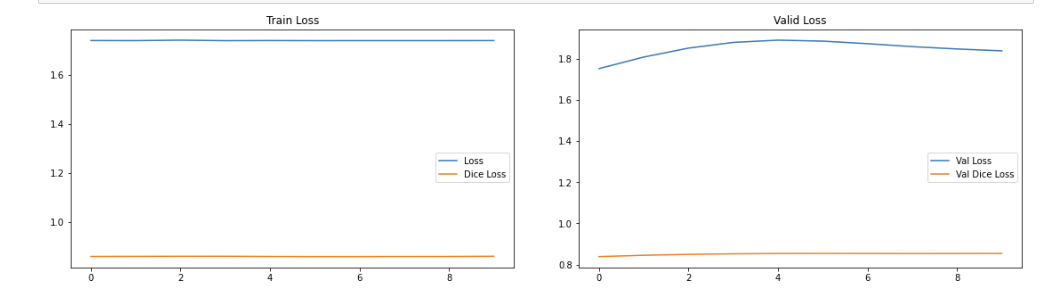
mean_iou: 0.9396369709541113
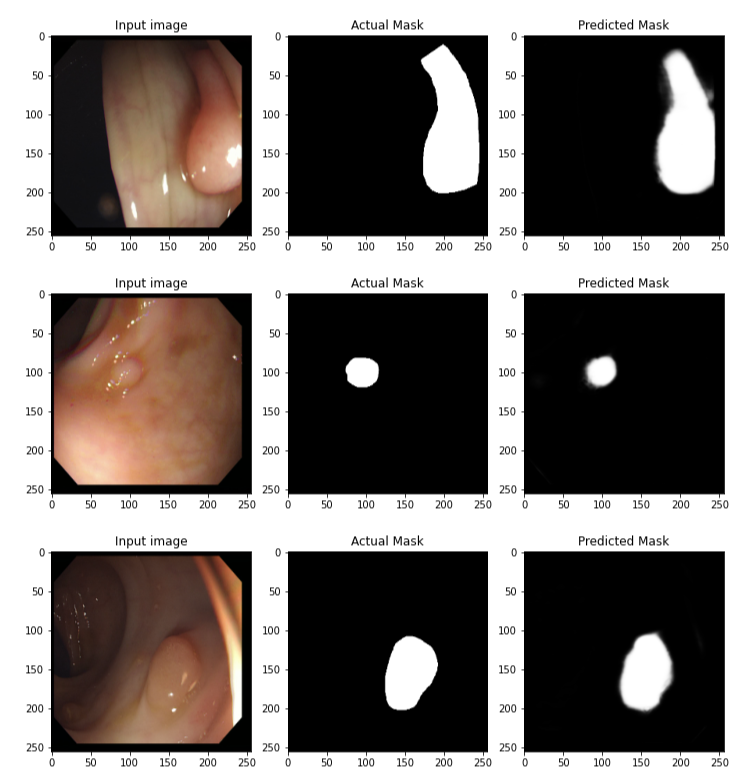

### 모델 3: U-Net 개선
checkpoint가 저장되지 않는 문제가 있어서 해결하던 중 끝났지만
loss 그래프라 2번 모델보다 정상화되어보인다. 
segmentation은 아직 미완인 것 같지만 훈련 시간이 너무 짧기 때문에 에포크를 더 돌리면 개선될 가능성이 있지 않을까.

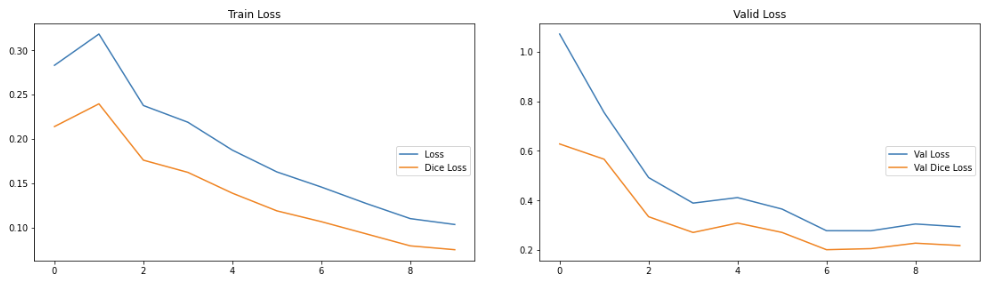
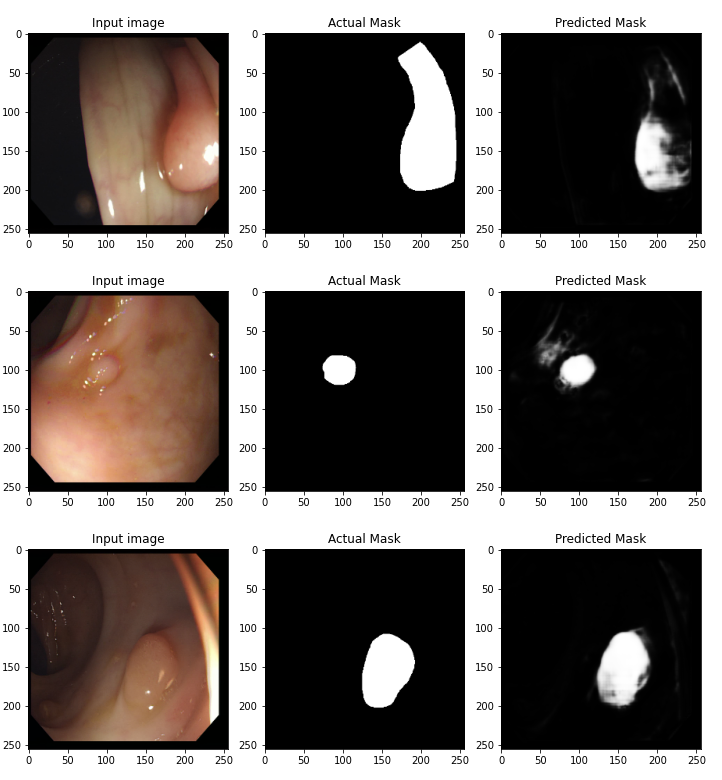

## 데이터 수집

In [1]:
# 커널 재시작 후
# import tensorflow as tf
# tf.keras.backend.clear_session()

In [2]:
# 필요 라이브러리 로딩
from __future__ import absolute_import, division
from __future__ import print_function, unicode_literals

import os
import time
import shutil
import functools

import numpy as np
import matplotlib.pyplot as plt
%matplotlib inline
import matplotlib as mpl
mpl.rcParams['axes.grid'] = False
mpl.rcParams['figure.figsize'] = (12,12)

from sklearn.model_selection import train_test_split
from sklearn.metrics import confusion_matrix
import matplotlib.image as mpimg
import pandas as pd
from PIL import Image
from IPython.display import clear_output

import tensorflow as tf
import tensorflow_addons as tfa
print(tf.__version__)

from tensorflow.keras import layers
from tensorflow.keras import losses
from tensorflow.keras import models

2.6.0


In [3]:
# GPU 메모리 설정
gpus = tf.config.experimental.list_physical_devices('GPU')
if gpus:
    try:
        for gpu in gpus:
            tf.config.experimental.set_memory_growth(gpu, True)
        print("GPU 메모리 자동 할당 설정 완료")
    except RuntimeError as e:
        print(f"GPU 설정 오류: {e}")

GPU 메모리 자동 할당 설정 완료


In [4]:
# !mkdir -p ~/aiffel/medical
# !ln -s ~/data/* ~/aiffel/medical

In [5]:
DATASET_PATH = os.path.join(os.getenv('HOME'), 'aiffel', 'medical')

img_dir = os.path.join(DATASET_PATH, "train")
label_dir = os.path.join(DATASET_PATH, "train_labels")

In [6]:
x_train_filenames = [os.path.join(img_dir, filename) for filename in os.listdir(img_dir)]
x_train_filenames.sort()
y_train_filenames = [os.path.join(label_dir, filename) for filename in os.listdir(label_dir)]
y_train_filenames.sort()

In [7]:
x_train_filenames, x_test_filenames, y_train_filenames, y_test_filenames = \
                    train_test_split(x_train_filenames, y_train_filenames, test_size=0.2)

In [8]:
num_train_examples = len(x_train_filenames)
num_test_examples = len(x_test_filenames)

print("Number of training examples: {}".format(num_train_examples))
print("Number of test examples: {}".format(num_test_examples))

Number of training examples: 240
Number of test examples: 60


라벨: 입력이미지와 동일한 사이즈의 1채널 이미지 (segmented mask)

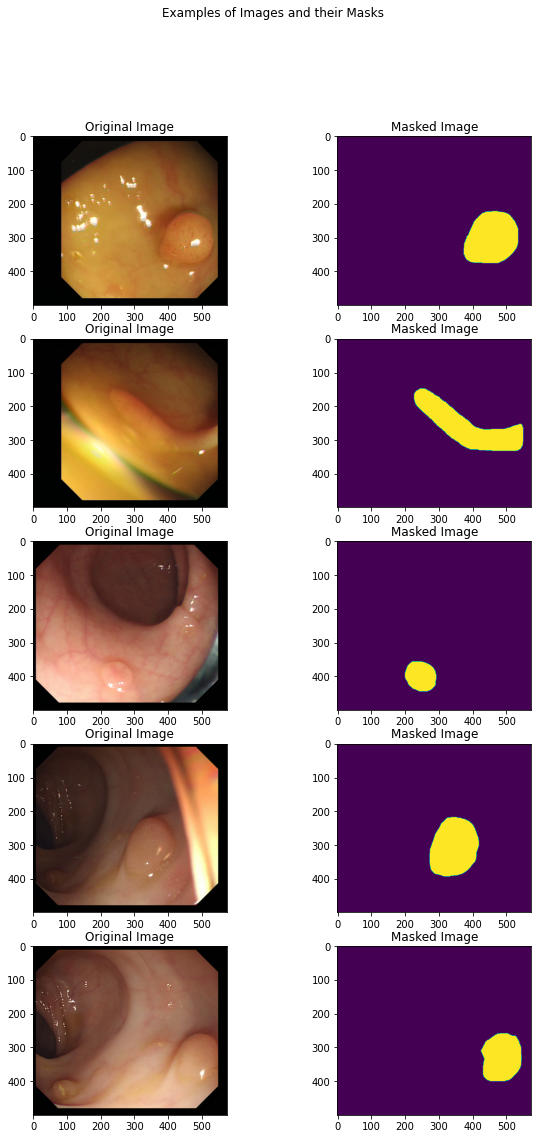

In [9]:
display_num = 5

r_choices = np.random.choice(num_train_examples, display_num)

plt.figure(figsize=(10, 18))
for i in range(0, display_num * 2, 2):
    img_num = r_choices[i // 2]
    x_pathname = x_train_filenames[img_num]
    y_pathname = y_train_filenames[img_num]

    plt.subplot(display_num, 2, i + 1)
    plt.imshow(Image.open(x_pathname))
    plt.title("Original Image")

    example_labels = Image.open(y_pathname)
    label_vals = np.unique(example_labels)

    plt.subplot(display_num, 2, i + 2)
    plt.imshow(example_labels)
    plt.title("Masked Image")
    
plt.suptitle("Examples of Images and their Masks")
plt.show()

## 데이터 전처리

In [10]:
# Set hyperparameters

image_size = 256 #256
img_shape = (image_size, image_size, 3)
batch_size = 8
max_epochs = 10

In [11]:
# 입력 파이프라인 설계
def _process_pathnames(fname, label_path):
    # We map this function onto each pathname pair
    """
    이미지와 레이블 경로를 입력받아 전처리된 이미지 쌍을 반환하는 함수
    
    Args:
        fname (str): 원본 이미지 파일 경로
        label_path (str): 레이블(세그멘테이션) 이미지 파일 경로
    
    Returns:
        tuple: (전처리된 이미지, 전처리된 레이블 이미지)
            - img: 정규화된 3채널 RGB 이미지 텐서
            - label_img: 정규화된 1채널 그레이스케일 레이블 이미지 텐서
    
    처리 과정:
        1. BMP 형식의 이미지 파일을 읽어서 디코딩
        2. 레이블 이미지를 그레이스케일로 변환
        3. 이미지를 지정된 크기로 리사이즈
        4. 픽셀 값을 0-1 범위로 정규화
    """
    # 원본 이미지 파일 읽기 및 디코딩 (3채널 BMP(바이트 문자열) > 텐서)
    img_str = tf.io.read_file(fname)
    img = tf.image.decode_bmp(img_str, channels=3)
    # 결과: [height, width, 3] 형태의 텐서
    
    # 레이블 이미지 파일 읽기 및 디코딩 (3채널 BMP)
    label_img_str = tf.io.read_file(label_path)
    label_img = tf.image.decode_bmp(label_img_str, channels=3)
    
    # 그레이스케일 변환
    label_img = tf.image.rgb_to_grayscale(label_img)
    
    # 고정 크기로 이미지 리사이즈
    resize = [image_size, image_size]
    img = tf.image.resize(img, resize)
    label_img = tf.image.resize(label_img, resize)
    
    # 정규화(0-1)
    scale = 1 / 255.
    img = tf.cast(img, dtype=tf.float32) * scale
    label_img = tf.cast(label_img, dtype=tf.float32) * scale

    return img, label_img

# 데이터 증강 - Shifting the image
def shift_img(output_img, label_img, width_shift_range, height_shift_range):
    """
    이미지를 수평 또는 수직으로 랜덤하게 이동시키는 함수
    
    Args:
        output_img (tensor): 입력 이미지 텐서
        label_img (tensor): 레이블 이미지 텐서
        width_shift_range (float): 이미지 너비의 비율로 표현된 수평 이동 범위 (0.0~1.0)
        height_shift_range (float): 이미지 높이의 비율로 표현된 수직 이동 범위 (0.0~1.0)
    
    Returns:
        tuple: (이동된 입력 이미지, 이동된 레이블 이미지)
    
    Note:
        - img_shape는 전역 변수로 이미지의 크기([height, width, channels])를 포함함
        - 이동 거리는 지정된 범위 내에서 랜덤하게 결정됨
        - 원본 이미지와 레이블 이미지는 동일한 거리만큼 이동됨
    """
    if width_shift_range or height_shift_range:
        if width_shift_range:
                width_shift_range = tf.random.uniform([],
                                                  -width_shift_range * img_shape[1],
                                                  width_shift_range * img_shape[1])
        if height_shift_range:
                height_shift_range = tf.random.uniform([],
                                                   -height_shift_range * img_shape[0],
                                                   height_shift_range * img_shape[0])
        output_img = tfa.image.translate(output_img,
                                         [width_shift_range, height_shift_range])
        label_img = tfa.image.translate(label_img,
                                        [width_shift_range, height_shift_range])
    return output_img, label_img

# 데이터 증강 - Flipping the image randomly
def flip_img(horizontal_flip, tr_img, label_img):
    """
    이미지를 좌우로 랜덤하게 뒤집는 함수
    
    Args:
        horizontal_flip (bool): 뒤집기 활성화 여부
        tr_img (tensor): 학습 이미지 텐서
        label_img (tensor): 레이블 이미지 텐서
    
    Returns:
        tuple: (뒤집어진 학습 이미지, 뒤집어진 레이블 이미지)
    
    Note:
        - horizontal_flip이 True일 때만 동작
        - 50% 확률로 이미지를 좌우로 뒤집음
        - 학습 이미지와 레이블 이미지가 동시에 뒤집어짐
    """
    if horizontal_flip:
        flip_prob = tf.random.uniform([], 0.0, 1.0)
        tr_img, label_img = tf.cond(tf.less(flip_prob, 0.5),
                                lambda: (tf.image.flip_left_right(tr_img), tf.image.flip_left_right(label_img)),
                                lambda: (tr_img, label_img))
    return tr_img, label_img

# 데이터 증강 - Main Function
def _augment(img,
             label_img,
             resize=None,
             scale=1, 
             hue_delta=0.,  
             horizontal_flip=True,  
             width_shift_range=0.05, 
             height_shift_range=0.05): 
    
    """
    다양한 데이터 증강 기법을 통합한 메인 함수
    
    Args:
        img (tensor): 입력 이미지 텐서
        label_img (tensor): 레이블 이미지 텐서
        resize (list, optional): 리사이즈할 크기 [height, width]
        scale (float): 픽셀 값 스케일링 팩터, 기본값 1
        hue_delta (float): 색조 조정 범위 by random factor, 기본값 0
        horizontal_flip (bool): 좌우 뒤집기 활성화 여부, 기본값 True
        width_shift_range (float): 수평 이동 범위 비율, 기본값 0.05
        height_shift_range (float): 수직 이동 범위 비율, 기본값 0.05
    
    Returns:
        tuple: (증강된 이미지, 증강된 레이블 이미지)
    
    데이터 증강 순서:
        1. 이미지 크기 조정 (resize가 지정된 경우)
        2. 색조 조정 (hue_delta가 0이 아닌 경우)
        3. 좌우 뒤집기 (horizontal_flip이 True인 경우)
        4. 이미지 이동 (width_shift_range 또는 height_shift_range가 0이 아닌 경우)
        5. 픽셀 값 스케일링 및 float32로 형변환
    """    
    if resize is not None:
        # Resize both images
        label_img = tf.image.resize(label_img, resize)
        img = tf.image.resize(img, resize)
  
    if hue_delta:
        img = tf.image.random_hue(img, hue_delta)
  
    img, label_img = flip_img(horizontal_flip, img, label_img)
    img, label_img = shift_img(img, label_img, width_shift_range, height_shift_range)
    label_img = tf.cast(label_img, dtype=tf.float32) * scale
    img = tf.cast(img, dtype=tf.float32) * scale
    return img, label_img

In [12]:
# 훈련 데이터셋 구성
def get_baseline_dataset(filenames,
                         labels,
                         preproc_fn=functools.partial(_augment),
                         threads=4,
                         batch_size=batch_size,
                         is_train=True):
    
    """
    훈련 또는 테스트용 데이터셋을 생성하는 함수
    
    Args:
        filenames (list): 입력 이미지 파일 경로 리스트
        labels (list): 레이블 이미지 파일 경로 리스트
        preproc_fn (function): 데이터 증강 함수, 기본값은 _augment 함수
        threads (int): 병렬 처리 스레드 수, 기본값 4
        batch_size (int): 배치 크기, 기본값은 전역 변수 batch_size
        is_train (bool): 훈련 데이터셋 여부, 기본값 True
    
    Returns:
        tf.data.Dataset: 전처리된 데이터셋 객체
    
    Note:
        - 훈련 데이터셋은 데이터 증강과 셔플링이 적용됨
        - 테스트 데이터셋은 전처리만 적용되고 증강과 셔플링은 적용되지 않음
    """
    # 전체 데이터 수 저장(셔플링용)
    num_x = len(filenames)
    
    # 파일 경로들로부터 tf.data.Dataset 객체 생성
    # zip처럼 이미지 파일과 레이블을 쌍으로 묶음
    dataset = tf.data.Dataset.from_tensor_slices((filenames, labels))
    
    # 모든 데이터에 대해 _process_pathnames 함수 적용
    # num_parallel_calls: 멀티스레딩으로 데이터 처리 속도 향상
    dataset = dataset.map(_process_pathnames, num_parallel_calls=threads)

    # 훈련 데이터셋인 경우에만 조건부 증강
    if is_train:
        #if preproc_fn.keywords is not None and 'resize' not in preproc_fn.keywords:
        #  assert batch_size == 1, "Batching images must be of the same size"
        dataset = dataset.map(preproc_fn, num_parallel_calls=threads)
        # 셔플링으로 모델이 데이터 순서를 기억하지 못하게 함
        dataset = dataset.shuffle(num_x * 10)
    
    dataset = dataset.batch(batch_size)
    return dataset

# ------------실행----------------#
train_dataset = get_baseline_dataset(x_train_filenames, # 학습 데이터
                                     y_train_filenames) # 정답 데이터

'''
RepeatDataset:
    - 훈련 데이터셋을 무한히 반복하도록 설정
    - epoch 가 끝나도 계속 제공되는 데이터
    - 모델 학습 시 한 에폭 당 스텝 수를 지정해야 함
''' 
train_dataset = train_dataset.repeat()
test_dataset = get_baseline_dataset(x_test_filenames,   # 테스트 데이터
                                    y_test_filenames,
                                    is_train=False)     # 증강과 셔플링 비활성화

In [13]:
# 생성된 훈련 데이터셋 확인
train_dataset

<RepeatDataset shapes: ((None, 256, 256, 3), (None, 256, 256, 1)), types: (tf.float32, tf.float32)>

/opt/conda/lib/python3.9/site-packages/matplotlib/backends/backend_agg.py:240: RuntimeWarning: Glyph 50896 missing from current font.
  font.set_text(s, 0.0, flags=flags)
/opt/conda/lib/python3.9/site-packages/matplotlib/backends/backend_agg.py:240: RuntimeWarning: Glyph 48376 missing from current font.
  font.set_text(s, 0.0, flags=flags)
/opt/conda/lib/python3.9/site-packages/matplotlib/backends/backend_agg.py:240: RuntimeWarning: Glyph 51060 missing from current font.
  font.set_text(s, 0.0, flags=flags)
/opt/conda/lib/python3.9/site-packages/matplotlib/backends/backend_agg.py:240: RuntimeWarning: Glyph 48120 missing from current font.
  font.set_text(s, 0.0, flags=flags)
/opt/conda/lib/python3.9/site-packages/matplotlib/backends/backend_agg.py:240: RuntimeWarning: Glyph 51648 missing from current font.
  font.set_text(s, 0.0, flags=flags)
/opt/conda/lib/python3.9/site-packages/matplotlib/backends/backend_agg.py:240: RuntimeWarning: Glyph 47112 missing from current font.
  font.set_

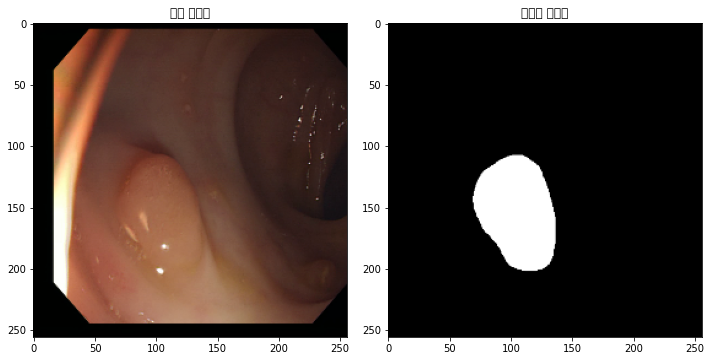

In [14]:
for images, labels in train_dataset.take(1):
    '''
    DEBUGGING
    
    기존 코드: img = images[0] 
    - 텐서 인덱싱 연산 방법으로, TF가 cpu -> gpu에서 연산하기 위해 데이터를 복사하는 과정에서 오류 발생
    
    수정: images_np = images.numpy()
    - 텐서를 CPU 메모리의 NumPy 배열로 변환
    - Matplotlib은 NumPy배열을 직접 사용하므로 GPU 오류가 발생하지 않음
    '''
    # GPU 텐서를 CPU로 가져와서 NumPy 배열로 변환
    images_np = images.numpy()
    labels_np = labels.numpy()
    
    # 이제 NumPy 배열로 시각화
    plt.figure(figsize=(10, 10))
    
    plt.subplot(1, 2, 1)
    plt.imshow(images_np[0])  # 첫 번째 이미지
    plt.title('원본 이미지')
    
    plt.subplot(1, 2, 2)
    plt.imshow(labels_np[0, :, :, 0], cmap='gray')  # 첫 번째 레이블 (그레이스케일)
    plt.title('레이블 이미지')
    
    plt.tight_layout()
    plt.show()

## 모델 빌드

Encoder-Decoder Architecture
- Encoder를 이용해 우리가 가진 Train data를 작은 차원의 공간에 압축하는 방식으로 동작합니다.
- Decoder는 Encoder가 압축한 데이터들을 우리가 원하는 label 데이터와 같도록 재생성합니다.
- 이렇게 생성된 데이터와 label 간의 차이가 작아지도록 Encoder와 Decoder의 파라미터들이 End-to-End로 학습됩니다.


### 인코더

In [15]:
# 인코더 구조 쌓기
# inputs: [batch_size, 256, 256, 3]
encoder = tf.keras.Sequential(name='encoder')

# conv-batchnorm-activation-maxpool
encoder.add(layers.Conv2D(64, (3, 3), padding='same'))
encoder.add(layers.BatchNormalization())
encoder.add(layers.Activation('relu'))
encoder.add(layers.Conv2D(64, (3, 3), strides=2, padding='same'))
encoder.add(layers.BatchNormalization())
encoder.add(layers.Activation('relu')) # conv1: [batch_size, 128, 128, 64]

encoder.add(layers.Conv2D(128, (3, 3), padding='same'))
encoder.add(layers.BatchNormalization())
encoder.add(layers.Activation('relu'))
encoder.add(layers.Conv2D(128, (3, 3), strides=2, padding='same'))
encoder.add(layers.BatchNormalization())
encoder.add(layers.Activation('relu')) # conv2: [batch_size, 64, 64, 128]

encoder.add(layers.Conv2D(256, (3, 3), padding='same'))
encoder.add(layers.BatchNormalization())
encoder.add(layers.Activation('relu'))
encoder.add(layers.Conv2D(256, (3, 3), strides=2, padding='same'))
encoder.add(layers.BatchNormalization())
encoder.add(layers.Activation('relu')) # conv3: [batch_size, 32, 32, 256]

encoder.add(layers.Conv2D(512, (3, 3), padding='same'))
encoder.add(layers.BatchNormalization())
encoder.add(layers.Activation('relu'))
encoder.add(layers.Conv2D(512, (3, 3), strides=2, padding='same'))
encoder.add(layers.BatchNormalization())
encoder.add(layers.Activation('relu')) # conv4-outputs: [batch_size, 16, 16, 512]

In [16]:
# 텐서플로 메모리 로그 활성화
import os
os.environ['TF_CPP_MIN_LOG_LEVEL'] = '0'
tf.debugging.set_log_device_placement(True)

In [17]:
# 혼합 정밀도(Mixed Precision) 학습 사용
# 16비트 부동소수점 사용으로 메모리 절약
from tensorflow.keras import mixed_precision
mixed_precision.set_global_policy('mixed_float16')

INFO:tensorflow:Mixed precision compatibility check (mixed_float16): OK
Your GPU will likely run quickly with dtype policy mixed_float16 as it has compute capability of at least 7.0. Your GPU: Tesla T4, compute capability 7.5


In [18]:
# Encoder 제대로 만들어졌는지 확인

bottleneck = encoder(tf.random.normal([batch_size, 256, 256, 3]))
print(bottleneck.shape)   # (batch_size, 16, 16, 512) 이 나오는지 확인

(8, 16, 16, 512)


### 디코더

In [19]:
# 디코더 구조 쌓기
# inputs: [batch_size, 16, 16, 512]
decoder = tf.keras.Sequential(name='decoder')

# conv_transpose-batchnorm-activation
decoder.add(layers.Conv2DTranspose(256, (3, 3), strides=2, padding='same'))
decoder.add(layers.BatchNormalization())
decoder.add(layers.Activation('relu')) # conv_transpose1: [batch_size, 32, 32, 256]
decoder.add(layers.Conv2D(256, (3, 3), padding='same'))
decoder.add(layers.BatchNormalization())
decoder.add(layers.Activation('relu'))

decoder.add(layers.Conv2DTranspose(128, (3, 3), strides=2, padding='same'))
decoder.add(layers.BatchNormalization())
decoder.add(layers.Activation('relu')) # conv_transpose2: [batch_size, 64, 64, 128]
decoder.add(layers.Conv2D(128, (3, 3), padding='same'))
decoder.add(layers.BatchNormalization())
decoder.add(layers.Activation('relu'))

decoder.add(layers.Conv2DTranspose(64, (3, 3), strides=2, padding='same'))
decoder.add(layers.BatchNormalization())
decoder.add(layers.Activation('relu')) # conv_transpose3: [batch_size, 128, 128, 64]
decoder.add(layers.Conv2D(64, (3, 3), padding='same'))
decoder.add(layers.BatchNormalization())
decoder.add(layers.Activation('relu'))

decoder.add(layers.Conv2DTranspose(32, (3, 3), strides=2, padding='same'))
decoder.add(layers.BatchNormalization())
decoder.add(layers.Activation('relu')) # conv transpose4-outputs: [batch_size, 256, 256, 32]
decoder.add(layers.Conv2D(32, (3, 3), padding='same'))
decoder.add(layers.BatchNormalization())
decoder.add(layers.Activation('relu'))

decoder.add(layers.Conv2DTranspose(1, 1, strides=1, padding='same', activation='sigmoid'))

In [20]:
# decoder 제대로 만들어졌는지 확인

predictions = decoder(bottleneck)
print(predictions.shape)    # (batch_size, 256, 256, 1) 이 나오는지 확인

(8, 256, 256, 1)


### 인코더-디코더 결합

In [21]:
# 인코더-디코더 모델 
ed_model = tf.keras.Sequential()

ed_model.add(encoder)
ed_model.add(decoder)

### U-Net Model Subclassing

- U-Net은 인코더-디코더 구조와 다르게 해당 레이어의 아웃풋이 바로 다음 레이어의 인풋이 되지 않는다. 따라서 시퀀셜을 사용할 수 없음

In [22]:
class Conv(tf.keras.Model):
    '''배치 정규화와 ReLU 활성화를 포함한 컨볼루션 블록'''
    def __init__(self, num_filters, kernel_size):
        super(Conv, self).__init__()
        self.conv = layers.Conv2D(num_filters, kernel_size, padding='same')
        self.bn = layers.BatchNormalization()

    def call(self, inputs, training=True):
        '''Conv 블록의 순전파'''
        x = self.conv(inputs)
        x = self.bn(x, training=training)
        x = layers.ReLU()(x)

        return x
    
class ConvBlock(tf.keras.Model):
    '''두 번째 컨볼루션에서 필터 수를 증가시키는 이중 컨볼루션 블록'''
    def __init__(self, num_filters):
        super(ConvBlock, self).__init__()
        self.conv1 = Conv(num_filters, 3)
        self.conv2 = Conv(num_filters * 2, 3)

    def call(self, inputs, training=True):
        '''ConvBlock 블록의 순전파'''
        encoder = self.conv1(inputs, training=training)
        encoder = self.conv2(encoder, training=training)

        return encoder

class ConvBlock_R(tf.keras.Model):
    '''필터 수를 유지하는 이중 컨볼루션 블록. 주로 디코더에서 사용'''
    def __init__(self, num_filters):
        super(ConvBlock_R, self).__init__()
        self.conv1 = Conv(num_filters, 3)
        self.conv2 = Conv(num_filters, 3)

    def call(self, inputs, training=True):
        '''ConvBlock_R의 순전파'''
        decoder = self.conv1(inputs, training=training)
        decoder = self.conv2(decoder, training=training)

        return decoder


class EncoderBlock(tf.keras.Model):
    '''컨볼루션 블록과 풀링으로 구성된 U-Net 인코더 블록'''
    def __init__(self, num_filters):
        super(EncoderBlock, self).__init__()
        self.conv_block = ConvBlock(num_filters)
        self.encoder_pool = layers.MaxPool2D()

    def call(self, inputs, training=True):
        '''EncoderBlock의 순전파'''
        encoder = self.conv_block(inputs, training=training)
        encoder_pool = self.encoder_pool(encoder)

        return encoder_pool, encoder


class DecoderBlock(tf.keras.Model):
    '''전치 컨볼루션, 스킵 연결 및 컨볼루션으로 구성된 U-Net 디코더 블록'''
    def __init__(self, num_filters):
        super(DecoderBlock, self).__init__()
        self.convT = layers.Conv2DTranspose(num_filters, 3, strides=2, padding='same')
        self.bn = layers.BatchNormalization()
        self.conv_block_r = ConvBlock_R(num_filters)

    def call(self, input_tensor, concat_tensor, training=True):
        '''DecoderBlock의 순전파'''
        decoder = self.convT(input_tensor)            
        decoder = self.bn(decoder, training=training)
        decoder = layers.ReLU()(decoder)
        decoder = tf.concat([decoder, concat_tensor], axis=-1)
        decoder = self.conv_block_r(decoder, training=training)

        return decoder
    
class UNet(tf.keras.Model):
    """
    이미지 세그멘테이션을 위한 U-Net 모델.
    인코더-디코더 구조와 스킵 연결을 통해 이미지의 문맥 정보와 공간 정보를 모두 활용.
    """
    def __init__(self):
        super(UNet, self).__init__()
        # 인코더 블록 (다운샘플링)
        self.encoder_block1 = EncoderBlock(64)
        self.encoder_block2 = EncoderBlock(128)
        self.encoder_block3 = EncoderBlock(256)
        self.encoder_block4 = EncoderBlock(512)
        
        # 중앙 블록 (병목 구간)
        self.center = ConvBlock(1024)

        # 디코더 블록 (업샘플링)
        self.decoder_block4 = DecoderBlock(512)
        self.decoder_block3 = DecoderBlock(256)
        self.decoder_block2 = DecoderBlock(128)
        self.decoder_block1 = DecoderBlock(64)
        
        # 출력층 (시그모이드 활성화를 통한 이진 세그멘테이션)
        self.output_conv = layers.Conv2D(1, 1, activation='sigmoid')

    def call(self, inputs, training=True):
        """
        U-Net 모델의 순전파.
       
        Args:
            inputs (tf.Tensor): 입력 이미지 텐서.
            training (bool, optional): 학습 모드 여부. 기본값은 True.
           
        Returns:
            tf.Tensor: 0~1 범위의 세그멘테이션 마스크.
        """
        # 인코더 경로 (컨텍스트 추출)
        encoder1_pool, encoder1 = self.encoder_block1(inputs)
        encoder2_pool, encoder2 = self.encoder_block2(encoder1_pool)
        encoder3_pool, encoder3 = self.encoder_block3(encoder2_pool)
        encoder4_pool, encoder4 = self.encoder_block4(encoder3_pool)
        
        # 병목 구간
        center = self.center(encoder4_pool)
        
        # 디코더 경로 (스킵 연결 통합)
        decoder4 = self.decoder_block4(center, encoder4)
        decoder3 = self.decoder_block3(decoder4, encoder3)
        decoder2 = self.decoder_block2(decoder3, encoder2)
        decoder1 = self.decoder_block1(decoder2, encoder1)
        
        # 최종 출력
        outputs = self.output_conv(decoder1)

        return outputs

In [23]:
# U-Net 모델 구현
unet_model = UNet()

## metrics와 loss functions 정의

binary cross entropy  
    - 각 픽셀을 독립적으로 분류하는데 효과적이며, 학습 초기 단계에서 그래디언트가 안정적인 성능을 보여줌  
dice_loss  
    - 예측과 정답 마스크의 겹치는 영역을 기준으로 계산하며, 클래스 불균형(전경-배경 픽셀 수 비율)에 덜 민감하다  
    - 1-Dice coefficient는 IoU와 수학적으로 직접 연관되어있음  
    - 학습 초기 불안정할 수 있다는 한계점 존재  
    
위 두가지를 같이 사용하면 상호보완적 효과를 제공  
    - BCE는 학습 초기에 안정적인 그래디언트 제공  
    - Dice Loss는 클래스 불균형 문제를 완화하고 IoU 향상에 직접 기여  
      
Mean IoU 성능 향상:  
    - Mean IoU는 세그멘테이션의 중요한 평가 지표  
    - Dice Loss는 IoU와 직접적인 관련이 있어 이 지표를 향상시키는 데 효과적  
    - BCE와 함께 사용하면 경계 부분의 정밀도도 함께 향상  


In [24]:
def dice_coeff(y_true, y_pred):
    smooth = 1e-10
    # Flatten
    y_true_f = tf.reshape(y_true, [-1])
    y_pred_f = tf.reshape(y_pred, [-1])
    intersection = tf.reduce_sum(y_true_f * y_pred_f)
    score = (2. * intersection + smooth) / (tf.reduce_sum(tf.square(y_true_f)) + \
                                            tf.reduce_sum(tf.square(y_pred_f)) + smooth)

    return score

def dice_loss(y_true, y_pred):
    loss = 1 - dice_coeff(y_true, y_pred)
    return loss

def bce_dice_loss(y_true, y_pred):
    loss = tf.reduce_mean(losses.binary_crossentropy(y_true, y_pred)) + \
          dice_loss(y_true, y_pred)
    return loss

In [34]:
optimizer = tf.keras.optimizers.Adam() # 기본 Learning rate 사용

코드 설명: 
세그멘테이션 모델이 픽셀별 정확도(BCE)와 영역 기반 유사도(Dice)를 동시에 최적화하는 함수들

##### dice_coeff 함수: Dice 계수 계산

입력 텐서를 1차원으로 평탄화
예측과 정답의 원소별 곱(교집합) 계산
Dice 계수 공식 적용: 2×교집합/(예측 영역 + 정답 영역)
수치 안정성을 위해 분모에 작은 값(smooth) 추가


###### dice_loss 함수: Dice 손실 계산

Dice 계수를 1에서 빼서 손실 값으로 변환
완벽한 예측(계수=1)일 때 손실은 0


##### bce_dice_loss 함수: 복합 손실 함수 생성

이진 교차 엔트로피(BCE) 손실 계산
Dice 손실 계산
두 손실을 동등하게 합산(가중치 없이)


###### 최적화: Adam 옵티마이저 설정

기본 학습률로 옵티마이저 초기화
이 복합 손실 함수를 최소화하도록 학습

## 모델 선택 및 컴파일

In [35]:
# 위에서 구성한 두가지 모델 중에서 하나를 선택해 주세요. 
# 여기서 선택을 바꾸어 다른 모델의 학습도 진행해 볼 수 있습니다. 

print('select the Encoder-Decoder model')
model = ed_model
checkpoint_dir =os.path.join(DATASET_PATH,'train_ckpt/ed_model')

# print('select the U-Net model')
# model = unet_model
# checkpoint_dir =os.path.join(DATASET_PATH,'train_ckpt/unet_model')

select the Encoder-Decoder model


In [36]:
# 컴파일
model.compile(optimizer=optimizer, loss=bce_dice_loss, metrics=[dice_loss])
predictions = model(tf.random.normal([batch_size, image_size, image_size, 3]))
print(predictions.shape)

(8, 256, 256, 1)


In [37]:
model.summary()

Model: "sequential"
_________________________________________________________________
Layer (type)                 Output Shape              Param #   
encoder (Sequential)         (8, 16, 16, 512)          4693056   
_________________________________________________________________
decoder (Sequential)         (8, 256, 256, 1)          2354913   
Total params: 7,047,969
Trainable params: 7,042,209
Non-trainable params: 5,760
_________________________________________________________________


## Callbacks

학습 중간 원하는 동작 설정
- 모니터링 및 파라미터 저장
- Learning rate 조절
- learning rate decay 구현

In [38]:
if not os.path.isdir(checkpoint_dir):
    os.makedirs(checkpoint_dir)

cp_callback = tf.keras.callbacks.ModelCheckpoint(checkpoint_dir,
                                                 save_weights_only=True,
                                                 monitor='val_loss',
                                                 mode='auto',
                                                 save_best_only=True,
                                                 verbose=0)

In [39]:
cos_decay = tf.keras.experimental.CosineDecay(1e-3, 
                                              max_epochs)
lr_callback = tf.keras.callbacks.LearningRateScheduler(cos_decay, verbose=1)

## 모델 훈련

In [40]:
## 예측 이미지 출력 함수
def print_images():
    for test_images, test_labels in test_dataset.take(1):
        predictions = model(test_images, training=False)

        # NumPy 배열로 변환하고 적절한 타입으로 조정
        test_images_np = test_images[0].numpy().astype(np.float32)
        test_labels_np = test_labels[0, :, :, 0].numpy().astype(np.float32)
        predictions_np = predictions[0, :, :, 0].numpy().astype(np.float32)
    
        plt.figure(figsize=(10, 20))
       
        # 원본 이미지 시각화
        plt.subplot(1, 3, 1)
        plt.imshow(test_images_np)
        plt.title("Input image")
        
        # 실제 마스크 시각화
        plt.subplot(1, 3, 2)
        plt.imshow(test_labels_np)
        plt.title("Actual Mask")

        # 예측 마스크 시각화
        plt.subplot(1, 3, 3)
        plt.imshow(predictions_np)
        plt.title("Predicted Mask")
        plt.show()

In [41]:
history = model.fit(train_dataset,
                    epochs=max_epochs,    # 10
                    steps_per_epoch=num_train_examples//batch_size,
                    validation_data=test_dataset,
                    validation_steps=num_test_examples//batch_size,
                    callbacks=[cp_callback, lr_callback]
                    )

Epoch 1/10

Epoch 00001: LearningRateScheduler setting learning rate to tf.Tensor(0.001, shape=(), dtype=float32).
30/30 [==============================] - 14s 219ms/step - loss: 1.5758 - dice_loss: 0.8353 - val_loss: 1.6551 - val_dice_loss: 0.8170
Epoch 2/10

Epoch 00002: LearningRateScheduler setting learning rate to tf.Tensor(0.00097552827, shape=(), dtype=float32).
30/30 [==============================] - 7s 179ms/step - loss: 1.5766 - dice_loss: 0.8351 - val_loss: 1.6282 - val_dice_loss: 0.8133
Epoch 3/10

Epoch 00003: LearningRateScheduler setting learning rate to tf.Tensor(0.0009045085, shape=(), dtype=float32).
30/30 [==============================] - 7s 180ms/step - loss: 1.5756 - dice_loss: 0.8347 - val_loss: 1.6106 - val_dice_loss: 0.8108
Epoch 4/10

Epoch 00004: LearningRateScheduler setting learning rate to tf.Tensor(0.00079389266, shape=(), dtype=float32).
30/30 [==============================] - 7s 181ms/step - loss: 1.5766 - dice_loss: 0.8344 - val_loss: 1.5995 - val_di

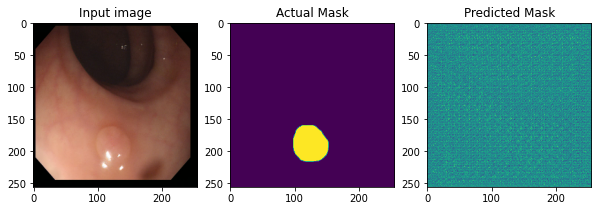

In [42]:
# print sample image after training
print_images()

### History 시각화

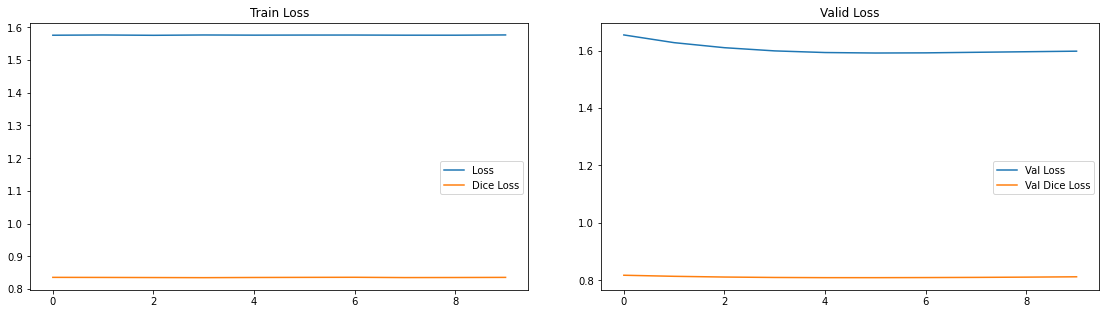

In [43]:
dice_loss = history.history['dice_loss']
loss = history.history['loss']
val_dice_loss = history.history['val_dice_loss']
val_loss = history.history['val_loss']

epochs_range = range(max_epochs)

plt.figure(figsize=(16, 5))
plt.subplot(1, 2, 1)
plt.plot(epochs_range, loss, label='Loss')
plt.plot(epochs_range, dice_loss, label='Dice Loss')
plt.legend(loc='best', bbox_to_anchor=(1, 0.5))
plt.title('Train Loss')

plt.subplot(1, 2, 2)
plt.plot(epochs_range, val_loss, label='Val Loss')
plt.plot(epochs_range, val_dice_loss, label='Val Dice Loss')
plt.legend(loc='best', bbox_to_anchor=(1, 0.5))
plt.title('Valid Loss')

#서브플롯 간 간격 조정
plt.tight_layout(pad=3.0, w_pad=5.0)
plt.show()

### 저장된 모델의 가중치 불러오기

In [44]:
# 원하는 모델을 불러올 수 있도록 적절히 주석을 처리하세요
# checkpoint_dir = os.path.join(DATASET_PATH, 'ed_ckpt/ed_model')
checkpoint_dir = os.path.join(DATASET_PATH, 'unet_ckpt/unet_model')

# restoring the latest checkpoint in checkpoint_dir
model.load_weights(checkpoint_dir)

## 모델 평가

Mean IoU(Intersection over Union)는 이미지 세그멘테이션 모델의 성능을 평가하는 핵심 지표입니다.
- 정의: 예측된 영역과 실제 영역의 겹치는 부분(교집합)을 두 영역의 합집합으로 나눈 값
- 수식: IoU = (예측 ∩ 실제) / (예측 ∪ 실제)
- 범위: 0(완전 불일치)에서 1(완전 일치) 사이의 값

Mean IoU: 여러 클래스 또는 여러 이미지에 대한 IoU의 평균값

U-Net 세그멘테이션에서 Mean IoU의 중요성

형태 보존 평가
- U-Net은 객체의 정확한 경계와 형태를 보존하는 것이 핵심 목표
- IoU는 단순 픽셀 정확도보다 객체의 전체적 형태 보존을 더 잘 평가함


클래스 불균형 극복
- 의료 영상 등에서는 관심 영역(병변)이 전체 이미지에서 매우 작은 부분만 차지
- 단순 정확도는 이런 불균형에서 왜곡될 수 있지만, IoU는 상대적으로 강인함


경계 정확도 중시
- U-Net의 스킵 연결은 정교한 경계 정보 보존이 목적
- IoU는 경계 예측의 정확성에 민감하게 반응하여 이를 효과적으로 평가


기하학적 이해
- 세그멘테이션은 픽셀 분류를 넘어 객체의 기하학적 이해가 목표
- IoU는 객체의 위치, 크기, 형태를 모두 고려한 종합적 평가 제공


임상/실제 활용 연관성
- 의료 영상에서 병변의 크기나 형태는 진단에 중요
- IoU가 높을수록 실제 임상 활용 가치가 높음

Mean IoU는 단순히 정확도를 넘어 세그멘테이션의 품질을 평가하는 더 엄격하고 의미 있는 지표로, U-Net 모델이 추구하는 정교한 경계 검출과 형태 보존 능력을 효과적으로 측정합니다.



In [45]:
def mean_iou(y_true, y_pred, num_classes=2):
    # Flatten  
    y_true_f = tf.reshape(y_true, [-1])
    y_pred_f = tf.reshape(y_pred, [-1])

    y_true_f = tf.cast(tf.round(y_true_f), dtype=tf.int32).numpy()
    y_pred_f = tf.cast(tf.round(y_pred_f), dtype=tf.int32).numpy()

    # calculate confusion matrix
    labels = list(range(num_classes))
    current = confusion_matrix(y_true_f, y_pred_f, labels=labels)

    # compute mean iou
    intersection = np.diag(current)
    ground_truth_set = current.sum(axis=1)
    predicted_set = current.sum(axis=0)
    union = ground_truth_set + predicted_set - intersection

    IoU = intersection / union.astype(np.float32)
    return np.mean(IoU)

In [46]:
mean = []

for images, labels in test_dataset:
    predictions = model(images, training=False)
    m = mean_iou(labels, predictions)
    mean.append(m)

mean = np.array(mean)
mean = np.mean(mean)
print("mean_iou: {}".format(mean))

mean_iou: 0.4002039118443837


In [47]:
def print_images():
   for test_images, test_labels in test_dataset.take(1):
       # 예측 수행
       predictions = model(test_images, training=False)
       
       for i in range(batch_size):
           # NumPy 배열로 변환하고 적절한 타입으로 조정
           test_image_np = test_images[i].numpy().astype(np.float32)
           test_label_np = test_labels[i, :, :, 0].numpy().astype(np.float32)
           prediction_np = predictions[i, :, :, 0].numpy().astype(np.float32)
           
           plt.figure(figsize=(10, 20))
           
           # 원본 이미지 시각화
           plt.subplot(1, 3, 1)
           plt.imshow(test_image_np)
           plt.title("Input image")
           
           # 실제 마스크 시각화
           plt.subplot(1, 3, 2)
           plt.imshow(test_label_np, cmap='gray')
           plt.title("Actual Mask")
           
           # 예측 마스크 시각화
           plt.subplot(1, 3, 3)
           plt.imshow(prediction_np, cmap='gray')
           plt.title("Predicted Mask")
           
           plt.tight_layout()
           plt.show()

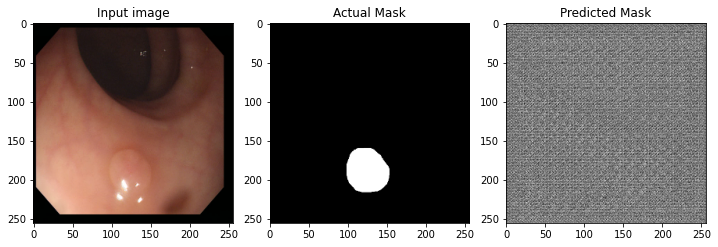

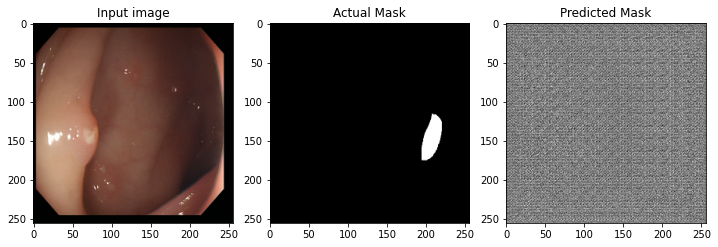

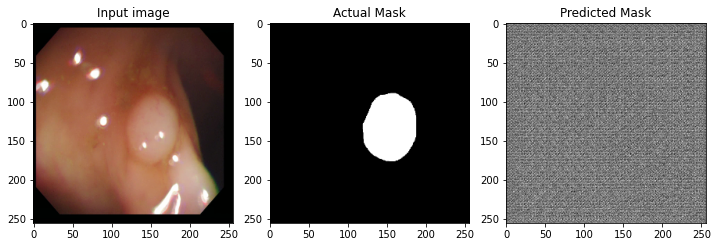

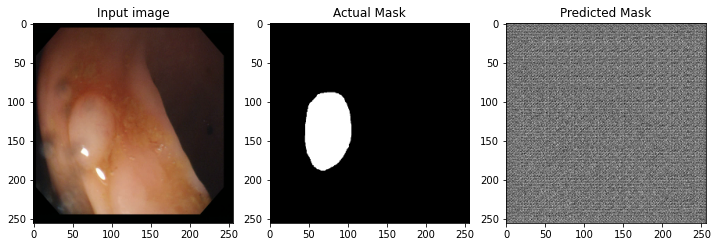

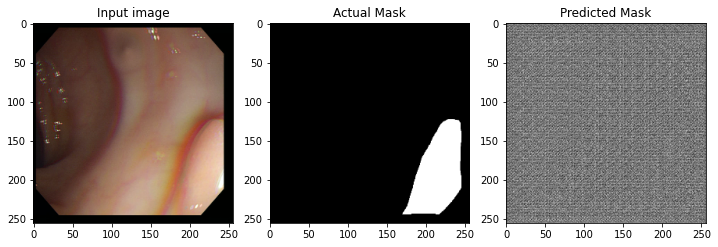

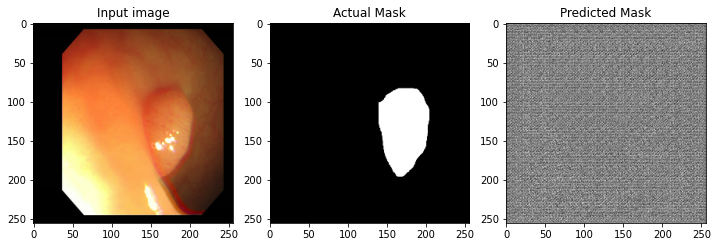

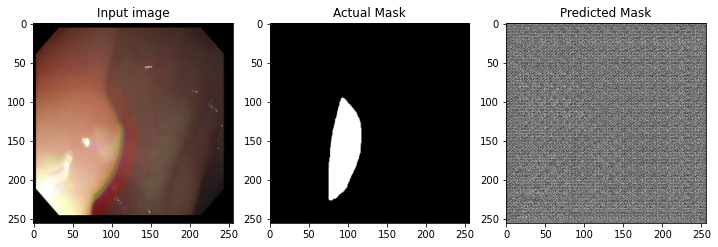

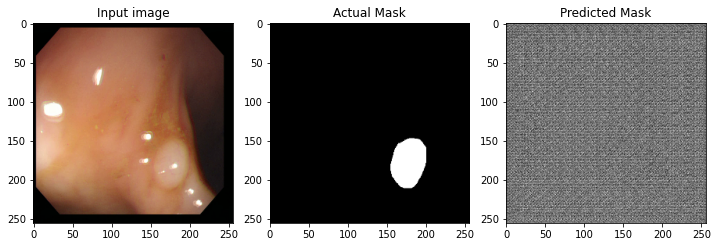

In [48]:
print_images()

# U-NET 성능 개선

Pre-trained 모델 활용

In [49]:
import tensorflow
import sklearn
import numpy

print(tensorflow.__version__)
print(sklearn.__version__)
print(numpy.__version__)

2.6.0
1.0
1.21.4


In [50]:
# 인코더를 pre-trained 모델로 교체하기 위해 
# 인코더로 활용할 모델의 레이어 구성 확인하기 
vgg16 = tf.keras.applications.VGG16(input_shape=img_shape,
                                         include_top=False,
                                         weights='imagenet')
layer_outputs = [layer.output for layer in vgg16.layers]
layer_outputs

58900480/58889256 [==============================] - 0s 0us/step


[<KerasTensor: shape=(None, 256, 256, 3) dtype=float32 (created by layer 'input_1')>,
 <KerasTensor: shape=(None, 256, 256, 64) dtype=float16 (created by layer 'block1_conv1')>,
 <KerasTensor: shape=(None, 256, 256, 64) dtype=float16 (created by layer 'block1_conv2')>,
 <KerasTensor: shape=(None, 128, 128, 64) dtype=float16 (created by layer 'block1_pool')>,
 <KerasTensor: shape=(None, 128, 128, 128) dtype=float16 (created by layer 'block2_conv1')>,
 <KerasTensor: shape=(None, 128, 128, 128) dtype=float16 (created by layer 'block2_conv2')>,
 <KerasTensor: shape=(None, 64, 64, 128) dtype=float16 (created by layer 'block2_pool')>,
 <KerasTensor: shape=(None, 64, 64, 256) dtype=float16 (created by layer 'block3_conv1')>,
 <KerasTensor: shape=(None, 64, 64, 256) dtype=float16 (created by layer 'block3_conv2')>,
 <KerasTensor: shape=(None, 64, 64, 256) dtype=float16 (created by layer 'block3_conv3')>,
 <KerasTensor: shape=(None, 32, 32, 256) dtype=float16 (created by layer 'block3_pool')>,


In [61]:
class Vgg16UNet(tf.keras.Model):
    """
    VGG16을 인코더로 사용하는 U-Net 모델
 
    기존 U-Net과 달리 인코더 부분을 처음부터 학습하지 않고,
    ImageNet으로 사전 학습된 VGG16 모델을 인코더로 활용
    특정 중간 레이어의 특징 맵을 추출하여 디코더 부분의 스킵 연결에 사용한다.
    """
    def __init__(self):
        super(Vgg16UNet, self).__init__()
        self.vgg16 = tf.keras.applications.VGG16(input_shape=img_shape,
                                         include_top=False,
                                         weights='imagenet')
        layer_outputs = [layer.output for layer in self.vgg16.layers]
        
        # decoder에 연결하기 위한 새로운 모델 객체
        self.vgg16_act = models.Model(inputs=self.vgg16.input, 
                                      outputs=[layer_outputs[2], 
                                               layer_outputs[5], 
                                               layer_outputs[9], 
                                               layer_outputs[13], 
                                               layer_outputs[17]])


        self.center = ConvBlock(1024)

        self.decoder_block4 = DecoderBlock(512)
        self.decoder_block3 = DecoderBlock(256)
        self.decoder_block2 = DecoderBlock(128)
        self.decoder_block1 = DecoderBlock(64)

        self.output_conv = layers.Conv2D(1, 1, activation='sigmoid')

    def call(self, inputs, training=True):
        # vgg16_act 모델의 출력으로 인코더 레이어의 역할을 대체
        encoder1, encoder2, encoder3, encoder4, center = self.vgg16_act(inputs) 

        decoder4 = self.decoder_block4(center, encoder4)
        decoder3 = self.decoder_block3(decoder4, encoder3)
        decoder2 = self.decoder_block2(decoder3, encoder2)
        decoder1 = self.decoder_block1(decoder2, encoder1)
        
        outputs = self.output_conv(decoder1)

        return outputs

In [62]:
# 모델 객체 생성
vgg16unet = Vgg16UNet()

### 오류방지: 모델 훈련 전 옵티마이저 정책 확인

In [53]:
# 옵티마이저 래핑 오류 디버깅: 현재 정책 확인
print(tf.keras.mixed_precision.global_policy())

<Policy "mixed_float16">


In [60]:
# 혼합 정밀도 사용하지 않기
tf.keras.mixed_precision.set_global_policy('float32')

# 이후 모델 재생성해줘야 함!

In [55]:
# 옵티마이저 생성 
# optimizer = tf.keras.optimizers.Adam()

# 충돌 방지: 손실 함수 재정의
def dice_coeff_2(y_true, y_pred):
    smooth = 1e-10
    # Flatten
    y_true_f = tf.reshape(y_true, [-1])
    y_pred_f = tf.reshape(y_pred, [-1])
    intersection = tf.reduce_sum(y_true_f * y_pred_f)
    score = (2. * intersection + smooth) / (tf.reduce_sum(tf.square(y_true_f)) + 
                                           tf.reduce_sum(tf.square(y_pred_f)) + smooth)
    return score

def dice_loss_2(y_true, y_pred):
    return 1 - dice_coeff_2(y_true, y_pred)

def bce_dice_loss_2(y_true, y_pred):
    bce = tf.keras.losses.BinaryCrossentropy(from_logits=False)
    return bce(y_true, y_pred) + dice_loss_2(y_true, y_pred)

# 모델 컴파일
model.compile(
    optimizer=tf.keras.optimizers.Adam(),
    loss=bce_dice_loss_2,
    metrics=[dice_loss_2]
)

### 모델 선택 & 훈련

In [63]:
# #1
#print('select the Encoder-Decoder model')
#model = ed_model
#checkpoint_dir =os.path.join(DATASET_PATH,'train_ckpt/ed_model')

# #2
# print('select the U-Net model')
# model = unet_model
# checkpoint_dir =os.path.join(DATASET_PATH,'train_ckpt/unet_model')

# 3
print('select the Vgg16 pre-trained + U-Net model')
model = vgg16unet
checkpoint_dir =os.path.join(DATASET_PATH,'train_ckpt/vgg16unet_model')

select the Vgg16 pre-trained + U-Net model


In [64]:
cos_decay = tf.keras.experimental.CosineDecay(1e-3, 
                                              max_epochs)
lr_callback = tf.keras.callbacks.LearningRateScheduler(cos_decay, verbose=1)

In [65]:
# 컴파일
model.compile(optimizer=optimizer, loss=bce_dice_loss_2, metrics=[dice_loss_2])
predictions = model(tf.random.normal([batch_size, image_size, image_size, 3]))
print(predictions.shape)

(8, 256, 256, 1)


In [66]:
model.summary()

Model: "vgg16u_net_1"
_________________________________________________________________
Layer (type)                 Output Shape              Param #   
vgg16 (Functional)           (None, 8, 8, 512)         14714688  
_________________________________________________________________
model_1 (Functional)         [(None, 256, 256, 64), (N 14714688  
_________________________________________________________________
conv_block_6 (ConvBlock)     multiple                  0 (unused)
_________________________________________________________________
decoder_block_8 (DecoderBloc multiple                  9444864   
_________________________________________________________________
decoder_block_9 (DecoderBloc multiple                  2952960   
_________________________________________________________________
decoder_block_10 (DecoderBlo multiple                  739200    
_________________________________________________________________
decoder_block_11 (DecoderBlo multiple                 

In [67]:
history_vgg16unet = model.fit(
                    train_dataset,
                    epochs=max_epochs,    # 10
                    steps_per_epoch=num_train_examples//batch_size,
                    validation_data=test_dataset,
                    validation_steps=num_test_examples//batch_size,
                    callbacks=[cp_callback, lr_callback]
                    )

Epoch 1/10

Epoch 00001: LearningRateScheduler setting learning rate to tf.Tensor(0.001, shape=(), dtype=float32).
30/30 [==============================] - 28s 604ms/step - loss: 1.0013 - dice_loss_2: 0.7266 - val_loss: 10.8441 - val_dice_loss_2: 1.0000
Epoch 2/10

Epoch 00002: LearningRateScheduler setting learning rate to tf.Tensor(0.00097552827, shape=(), dtype=float32).
30/30 [==============================] - 19s 600ms/step - loss: 0.8983 - dice_loss_2: 0.6996 - val_loss: 1.5620 - val_dice_loss_2: 0.9646
Epoch 3/10

Epoch 00003: LearningRateScheduler setting learning rate to tf.Tensor(0.0009045085, shape=(), dtype=float32).
30/30 [==============================] - 19s 579ms/step - loss: 0.8812 - dice_loss_2: 0.6841 - val_loss: 1.8578 - val_dice_loss_2: 0.9999
Epoch 4/10

Epoch 00004: LearningRateScheduler setting learning rate to tf.Tensor(0.00079389266, shape=(), dtype=float32).
30/30 [==============================] - 19s 582ms/step - loss: 0.8713 - dice_loss_2: 0.6790 - val_los

In [68]:
history

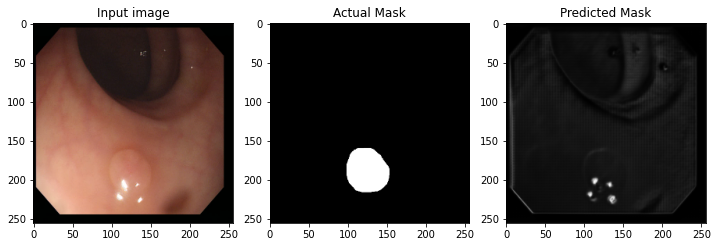

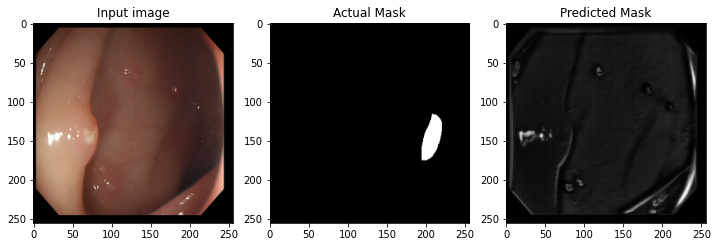

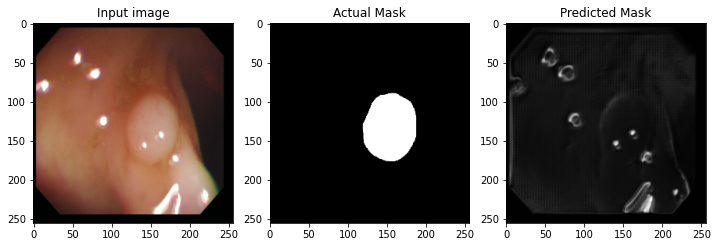

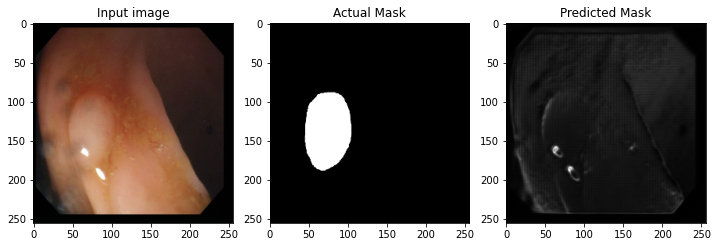

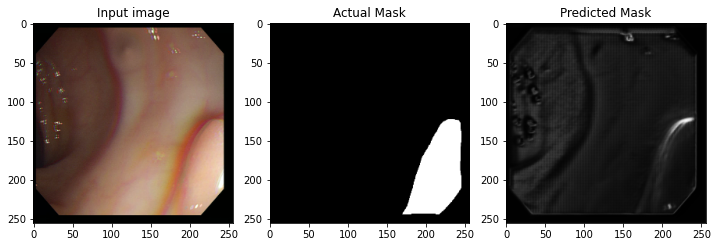

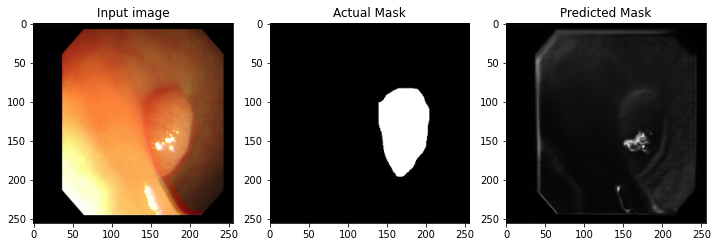

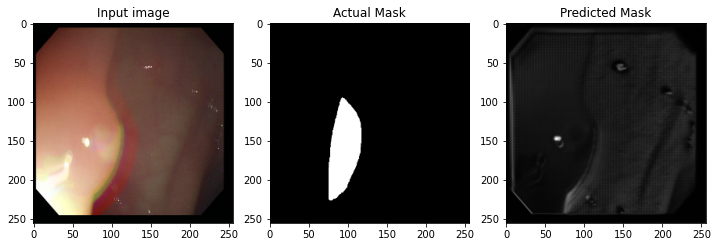

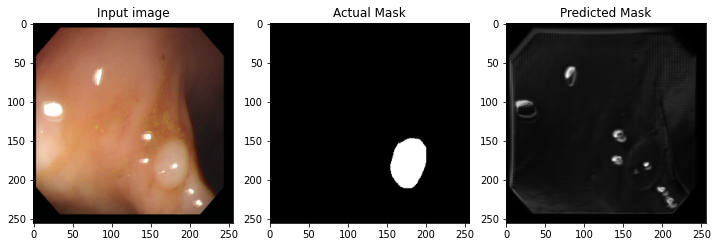

In [69]:
print_images()

In [73]:
dice_loss = history.history['dice_loss_2']
loss = history.history['loss']
val_dice_loss = history.history['val_dice_loss_2']
val_loss = history.history['val_loss']

epochs_range = range(max_epochs)

plt.figure(figsize=(16, 5))
plt.subplot(1, 2, 1)
plt.plot(epochs_range, loss, label='Loss')
plt.plot(epochs_range, dice_loss_2, label='Dice Loss')
plt.legend(loc='best', bbox_to_anchor=(1, 0.5))
plt.title('Train Loss')

plt.subplot(1, 2, 2)
plt.plot(epochs_range, val_loss, label='Val Loss')
plt.plot(epochs_range, val_dice_loss_2, label='Val Dice Loss')
plt.legend(loc='best', bbox_to_anchor=(1, 0.5))
plt.title('Valid Loss')

#서브플롯 간 간격 조정
plt.tight_layout(pad=3.0, w_pad=5.0)
plt.show()

KeyError: 'dice_loss_2'

In [74]:
checkpoint_dir = os.path.join(DATASET_PATH, 'train_ckpt/vgg16unet_model')

# restoring the latest checkpoint in checkpoint_dir
model.load_weights(checkpoint_dir)

NotFoundError: Unsuccessful TensorSliceReader constructor: Failed to find any matching files for /aiffel/aiffel/medical/train_ckpt/vgg16unet_model

In [134]:
import os
# 체크포인트 디렉토리가 존재하는지 확인
print(os.path.exists('/aiffel/aiffel/medical/train_ckpt'))
# 디렉토리 내용 확인
print(os.listdir('/aiffel/aiffel/medical/train_ckpt') if os.path.exists('/aiffel/aiffel/medical/train_ckpt') else "디렉토리가 존재하지 않음")

True
['checkpoint', 'unet_model.data-00000-of-00001', 'unet_model', 'unet_model.index']
